In [15]:
"""
1.1 
"""
import pandas as pd
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("machine_service_risk.csv")
print("Initial shape:", df.shape)
print("Initial missing values:\n", df.isnull().sum().sort_values(ascending=False).head(10))

# Remove non-predictive identifier
cleaned_df = df.drop(columns=["Asset_ID"]).copy()

# Treat missing values appropriately: median for numeric features, mode for categorical features
for col in cleaned_df.columns:
    if pd.api.types.is_numeric_dtype(cleaned_df[col]):
        cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].median())
    else:
        cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].mode()[0])

Initial shape: (2149, 34)
Initial missing values:
 Maintenance_Plan             446
Asset_ID                       0
Equipment_Age_Months           0
Service_Contract               0
Operating_Zone                 0
Average_Load_Tonnes            0
Dust_Exposure_Level            0
Weekly_Idle_Hours              0
Daily_Operating_Hours          0
Lubrication_Quality_Score      0
dtype: int64


In [16]:
# Encode categorical variables using meaningful numeric codes
cleaned_df["Service_Contract"] = cleaned_df["Service_Contract"].map({"Standard": 0, "Extended": 1})
cleaned_df["Operating_Zone"] = cleaned_df["Operating_Zone"].map({"Central": 0, "North": 1, "Coastal": 2, "Remote": 3})
cleaned_df["Maintenance_Plan"] = cleaned_df["Maintenance_Plan"].map({"Basic": 0, "Enhanced": 1, "Premium": 2})
cleaned_df["Dust_Exposure_Level"] = cleaned_df["Dust_Exposure_Level"].map({"Low": 0, "High": 1})
cleaned_df["Intermittent_Shutdown"] = cleaned_df["Intermittent_Shutdown"].map({"No": 0, "Yes": 1})

# Separate target and predictors, then standardise the predictors
X = cleaned_df.drop(columns=["Major_Service_Required"])
y = cleaned_df["Major_Service_Required"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Prepared feature matrix shape:", X.shape)
print("Target distribution:\n", y.value_counts().sort_index())


Prepared feature matrix shape: (2149, 32)
Target distribution:
 Major_Service_Required
0    1389
1     760
Name: count, dtype: int64


In [17]:
"""
1.2 
"""
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=8)
selector.fit(X_scaled, y)

scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
})

selected_top_8 = scores.sort_values(by="Score", ascending=False).head(8)
print(selected_top_8.to_string(index=False))

                     Feature      Score
  Mechanical_Condition_Score 329.785969
Maintenance_Compliance_Score 266.590232
             Error_Log_Alert 222.994948
         Sensor_Health_Score 127.915191
   Irregular_Vibration_Alert 113.792711
    Cooling_Efficiency_Score   6.887456
       Coolant_Temperature_C   3.900444
            Maintenance_Plan   2.744996


In [18]:
"""
1.3 
"""
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

estimator = LogisticRegression(max_iter=1000, random_state=42)
selector = RFE(estimator=estimator, n_features_to_select=8, step=1)
selector.fit(X_scaled, y)

selected_features = X.columns[selector.support_]
print("Selected feature names:")
print(selected_features.tolist())

Selected feature names:
['Dust_Exposure_Level', 'Average_Bearing_Temperature_C', 'Coolant_Temperature_C', 'Sensor_Health_Score', 'Mechanical_Condition_Score', 'Error_Log_Alert', 'Irregular_Vibration_Alert', 'Maintenance_Compliance_Score']


In [19]:
"""
1.4 
"""

#Common predictors:Coolant_Temperature_C, Error_Log_Alert, Irregular_Vibration_Alert, Maintenance_Compliance_Score, Mechanical_Condition_Score, Snsor_Health_Score.
#both methods agree on the strongest maintenance indicators, especially mechanical condition, maintenance compliance, error logs and vibration alerts. The differences reflect that SelectKBest ranks each feature individually, while RFE evaluates feature subsets and accounts for redundancy among correlated predictors.

'\n1.4 \n'

In [20]:
"""
2.1 
"""
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

rfe_predictors = X[selected_features]

X_train, X_test, y_train, y_test = train_test_split(
    rfe_predictors,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

log_reg = LogisticRegression(max_iter=1000, random_state=42)
decision_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

log_reg.fit(X_train, y_train)
decision_tree.fit(X_train, y_train)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

Training size: (1611, 8)
Test size: (538, 8)


In [21]:
"""
2.2 
"""
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


def evaluate_classifier(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"False Negatives: {fn}")
    print("Confusion Matrix:")
    print(cm)
    print()
    return {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1, "False Negatives": fn, "Confusion Matrix": cm}

log_reg_pred = log_reg.predict(X_test)
dt_pred = decision_tree.predict(X_test)

log_reg_metrics = evaluate_classifier(y_test, log_reg_pred, "Logistic Regression")
dt_metrics = evaluate_classifier(y_test, dt_pred, "Decision Tree")

=== Logistic Regression ===
Accuracy : 0.8271
Precision: 0.7566
Recall   : 0.7526
F1-Score : 0.7546
False Negatives: 47
Confusion Matrix:
[[302  46]
 [ 47 143]]

=== Decision Tree ===
Accuracy : 0.9033
Precision: 0.8594
Recall   : 0.8684
F1-Score : 0.8639
False Negatives: 25
Confusion Matrix:
[[321  27]
 [ 25 165]]



In [22]:
"""
2.3 The Decision Tree is preferred for this maintenance triage task because it has a higher recall and fewer false negatives. In this context, a false negative is especially costly because a high-risk asset may be missed and then fail before inspection. A missed failure can disrupt service, raise emergency repair costs and reduce asset life.
2.4 A single train-test split is not enough because the result depends on one particular random split. A more reliable estimate of future performance should use cross-validation (for example, 5-fold cross-validation) to average the model's performance across several train/validation splits and reduce the risk of overestimating performance on a lucky split.
"""
print(f"Logistic Regression recall: {log_reg_metrics['Recall']:.4f}; false negatives: {log_reg_metrics['False Negatives']}")
print(f"Decision Tree recall: {dt_metrics['Recall']:.4f}; false negatives: {dt_metrics['False Negatives']}")


#

Logistic Regression recall: 0.7526; false negatives: 47
Decision Tree recall: 0.8684; false negatives: 25


In [23]:
"""
3.1 
"""
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("grid_restoration.csv")
print("Initial missing values:\n", df.isnull().sum())

X = df.drop(columns=["Incident_ID", "Restoration_Time_Minutes"]).copy()
y = df["Restoration_Time_Minutes"].copy()

# Impute missing values appropriately
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].fillna(X[col].median())
    else:
        X[col] = X[col].fillna(X[col].mode()[0])



Initial missing values:
 Incident_ID                     0
Affected_Line_Length_km         0
Fault_Category                 30
Grid_Load_Level                30
Dispatch_Window                30
Crew_Type                       0
Dispatch_Delay_Minutes          0
Technician_Experience_Years    30
Restoration_Time_Minutes        0
dtype: int64


In [24]:
# Encode categorical predictors as numeric codes
for col in X.select_dtypes(include=["object"]).columns:
    X[col] = X[col].astype("category").cat.codes

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_proc = scaler.fit_transform(X_train)
X_test_proc = scaler.transform(X_test)

print("Training shape:", X_train_proc.shape)
print("Test shape:", X_test_proc.shape)

Training shape: (800, 7)
Test shape: (200, 7)


/tmp/ipykernel_24663/4274358980.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include=["object"]).columns:


In [30]:
"""
3.2 
"""
import numpy as np
import matplotlib.pyplot as plt

X_train_array = X_train_proc.astype(float)
y_train_array = y_train.to_numpy(dtype=float)

Xb = np.hstack([np.ones((X_train_array.shape[0], 1)), X_train_array])

# Initialise weights to zero
theta = np.zeros(Xb.shape[1])
learning_rate = 0.01
iterations = 2000
cost_history = []

for i in range(iterations):
    predictions = Xb @ theta
    errors = predictions - y_train_array
    gradient = (2 / len(y_train_array)) * (Xb.T @ errors)
    theta -= learning_rate * gradient

    cost = np.mean((Xb @ theta - y_train_array) ** 2)
    cost_history.append(cost)



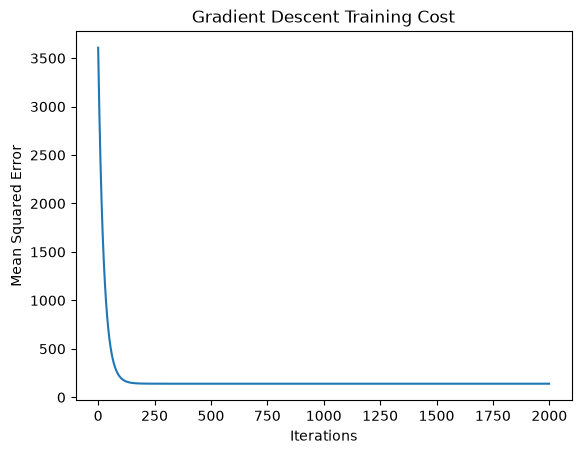

In [31]:
plt.plot(cost_history)
plt.title("Gradient Descent Training Cost")
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.show()


In [32]:
"""
3.3 
"""
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test_array = X_test_proc.astype(float)
X_test_b = np.hstack([np.ones((X_test_array.shape[0], 1)), X_test_array])
y_pred = X_test_b @ theta

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R²: {r2:.4f}")



"""
3.3
MAE measures the average absolute prediction error; lower values indicate the model is usually close to the true restoration time.
RMSE penalises larger errors more heavily than MAE; this is useful because large prediction errors can cause poor dispatch planning and customer communication.
R² shows how much variation in restoration time is explained by the model; values closer to 1 indicate stronger explanatory power."""

MAE: 7.46 minutes
RMSE: 10.42 minutes
R²: 0.7575


'\n3.3\nMAE measures the average absolute prediction error; lower values indicate the model is usually close to the true restoration time.\nRMSE penalises larger errors more heavily than MAE; this is useful because large prediction errors can cause poor dispatch planning and customer communication.\nR² shows how much variation in restoration time is explained by the model; values closer to 1 indicate stronger explanatory power.'

In [33]:
"""
4.1 
"""
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


df = pd.read_csv("smart_building_profiles.csv")
X = df.drop(columns=["Building_ID"]).copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

silhouette_scores = {}
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

print("Silhouette scores for k = 2 to 6:")
for k, score in silhouette_scores.items():
    print(f"k={k}: {score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print("Selected k:", best_k)

Silhouette scores for k = 2 to 6:
k=2: 0.2683
k=3: 0.2849
k=4: 0.2586
k=5: 0.2246
k=6: 0.1948
Selected k: 3


Cluster sizes:
0    62
1    51
2    65
Name: count, dtype: int64


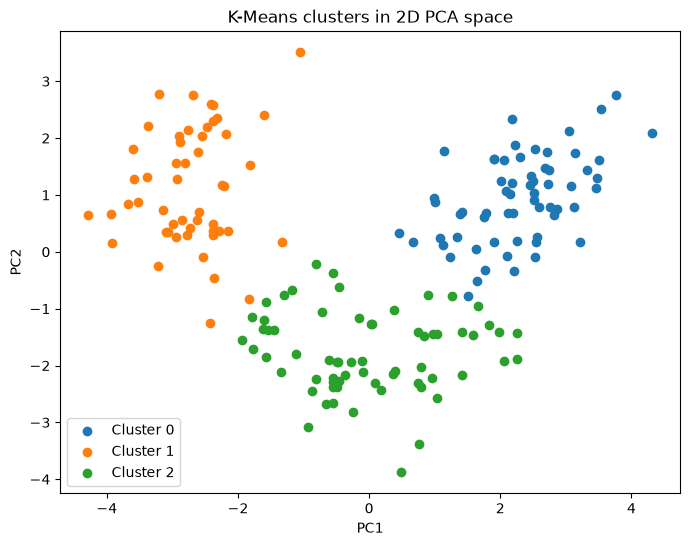

In [34]:
"""
4.2 
"""
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

final_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels = final_model.fit_predict(X_scaled)

cluster_counts = pd.Series(labels).value_counts().sort_index()
print("Cluster sizes:")
print(cluster_counts)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for cluster_id in sorted(set(labels)):
    plt.scatter(X_pca[labels == cluster_id, 0], X_pca[labels == cluster_id, 1], label=f"Cluster {cluster_id}")
plt.title("K-Means clusters in 2D PCA space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In [ ]:
"""
4.3 
"""
cluster_centres_original = scaler.inverse_transform(final_model.cluster_centers_)
profile_df = pd.DataFrame(cluster_centres_original, columns=X.columns)
print("Cluster-centre values in original units:\n")
print(profile_df.round(2).to_string(index=False))


"""
Cluster 0 represents efficient, lower-demand buildings with better insulation and lower HVAC untime intensity.
Cluster 1 captures high-usage, high-demand buildings with high occupancy, HVAC runtime and energy intensity.
Cluster 2 is intermediate/variable-use buildings with moderate demand and balanced operations."""

Cluster-centre values in original units:

 Avg_Indoor_Temperature_C  Daily_HVAC_Runtime_Hours  Occupancy_Density_per_1000m2  Heating_Setpoint_C  Monthly_Water_Use_m3  Insulation_Performance_Score  Solar_Gain_Index  Window_to_Wall_Ratio  Equipment_Diversity_Index  Peak_Demand_kW  Lighting_Efficiency_Index  Ventilation_Rate_ACH  Annual_Energy_Use_kWh_m2
                    20.18                      5.00                         49.33               19.24                194.34                          6.70             30.03                  0.29                       9.61          109.07                      53.27                  3.16                    220.05
                    19.63                      6.96                         48.35               20.37                177.60                          4.37              8.19                  0.45                       5.73          144.69                      34.60                  1.70                    123.81
                    18

'\nCluster 0 represents efficient, lower-demand buildings with better insulation and lower HVAC/runtime intensity.\nCluster 1 captures high-usage, high-demand buildings with strong occupancy, HVAC runtime and energy intensity.\nCluster 2 is intermediate/variable-use buildings with moderate demand and balanced operational characteristics.'